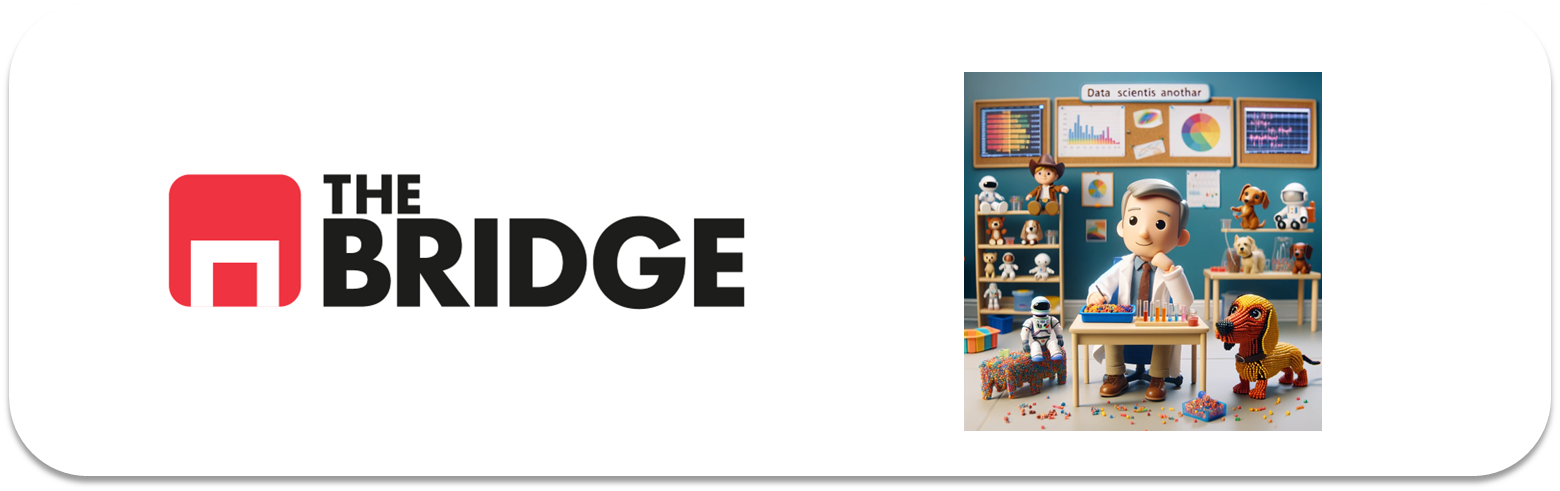

## PRACTICA OBLIGATORIA: ANÁLISIS UNIVARIANTE

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook. Te dejo una que vas a necesitar sí o sí

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

### #1 Preparación


### #1.1


Carga en un dataframe los datos del titanic a partir de un dataset de seaborn. Para ello:

* ejecuta ```python sns.get_dataset_names()```
* localiza el nombre que puede ser el adecuado para el ejercicio
* Asigna la salida de ```sns.load_dataset(<nombre_del_dataset>)``` a una variable "df_titanic"

In [57]:
sns.get_dataset_names()
df_titanic=sns.load_dataset('titanic')
df_titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### #1.2

Muestra una porción del dataset ("df_titanic") y su info general. ¿Hay nulos?

In [32]:
df_titanic.info() # en 'age', 'deck', 'embark' y 'embark_town' hay nulos

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


### #1.3

Obtén el porcentaje de nulos y decide que hacer con las columnas con nulos y ejecútalo. Además deshazte de la columna "parch" que no la emplearemos.

In [58]:
df_titanic.drop(columns=["parch"], inplace=True)

In [59]:
df_titanic.isna().mean()*100

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

np.int64(2)

In [ ]:
# Rellenamos los datos null de embarked con la moda de embarked
#pandas devuelve una serie con la moda, necesitamos acceder al primer elemento de la serie, si accedemos solo a la serie no aplicará la moda
df_titanic['embarked'] = df_titanic['embarked'].fillna(df_titanic["embarked"].mode()[0])
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [62]:
df_titanic["embarked"].isna().any()

np.False_

In [37]:
#Sustituimos los valores null de age por la mediana de las age teniendo en cuenta el sex, la pclass y who
df_titanic['age'] = df_titanic['age'].fillna(df_titanic.groupby(['sex','pclass','who'])['age'].transform('median'))
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,26.0,1,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [38]:
df_titanic["age"].isna().any()

np.False_

In [39]:
# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer

# imputer = IterativeImputer(random_state=0)
## Selecciona las columnas numéricas para ayudar a predecir
# df_titanic[['age', 'sex', 'fare','class','pclass','who']] = imputer.fit_transform(df_titanic[['age', 'sex', 'fare','class','pclass','who']])

### #1.4
Sobre el dataset "limpio". Rellena la tabla de descripción (muy breve) de lo que es cada columna en función de su nombre y los valores. Para ayudarte:
* Se trata del dataset que reune lo más parecido a un manifiesto de supervivientes y fallecidos en el viaje.
* sibsp: Es el numero de familiares que viajan con la persona indicada en el manifiesto (lista de pasajeros)
* embarked: Es la incial de la letra de la ciudad donde embarcó la persona.




| Columna/Variable | Descripción |
| ---------------- | ----------- |
| survived       | sobrevivió o no |
| pclass       | nivel de la clase del billete (numero) |
| sex       | sexo de la persona |
| age       | edad de la persona |
| sibsp       | numero de familiares acompañantes |
| fare       | tarifa |
| embarked       | inicial de la ciudad de embarque |
| class       | nivel de la clase del billete (palabra) |
| who       | tipo de persona (mujer, hombre o niño) |
| adult_male       | si es un hombre adulto o no |
| deck       | letra de la zona del barco donde estaba alojado |
| embark_town       | ciudad de embarque |
| alive       | si sobrevivió o no |
| alone       | si estaba solo o no en el trayecto |



### #1.5

Busca en internet las tres ciudades que visitó el Titanic antes de poner rumbo a su destino y llegar a alta mar. Cambia las iniciales por esos valores.

In [40]:
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,26.0,1,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [41]:
#Comprobamos que ambas columnas son exactemente iguales, inlcuidos los valores null
df_titanic["embarked"] = df_titanic["embarked"].str.replace("C","Cherbourg")

In [42]:
df_titanic["embarked"] = df_titanic["embarked"].str.replace("S","Southampton")

In [43]:
df_titanic["embarked"] = df_titanic["embarked"].str.replace("Q","Queenstown")

In [44]:
df_titanic["embarked"].equals(df_titanic["embark_town"])

True

In [45]:
#Ya que las dos columnas son exactemente iguales, eliminamos la columna embark_town
df_titanic.drop(columns=["embark_town"], inplace=True)

In [46]:
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,deck,alive,alone
0,0,3,male,22.0,1,7.2500,Southampton,Third,man,True,NaN,no,False
1,1,1,female,38.0,1,71.2833,Cherbourg,First,woman,False,C,yes,False
2,1,3,female,26.0,0,7.9250,Southampton,Third,woman,False,NaN,yes,True
3,1,1,female,35.0,1,53.1000,Southampton,First,woman,False,C,yes,False
4,0,3,male,35.0,0,8.0500,Southampton,Third,man,True,NaN,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,Southampton,Second,man,True,NaN,no,True
887,1,1,female,19.0,0,30.0000,Southampton,First,woman,False,B,yes,True
888,0,3,female,26.0,1,23.4500,Southampton,Third,woman,False,NaN,no,False
889,1,1,male,26.0,0,30.0000,Cherbourg,First,man,True,C,yes,True


### #2 Análisis

Sabiendo que el objetivo de nuestro análisis es hacer un estudio de la superviviencia y mortalidad en el viaje... Haz un análisis univariante completo y ordenado de las siguientes variables:
["survived","who","age","fare","class","embarked","alone"]
Nota: Si quieres añadir más, perfecto.

Separa el análisis en categóricas (incluyendo binarias) y numéricas. Muestra valores, gráficas y conclusiones/observaciones (2 o 3 por variable)

### #2.1 Categórico Binario 'survived'

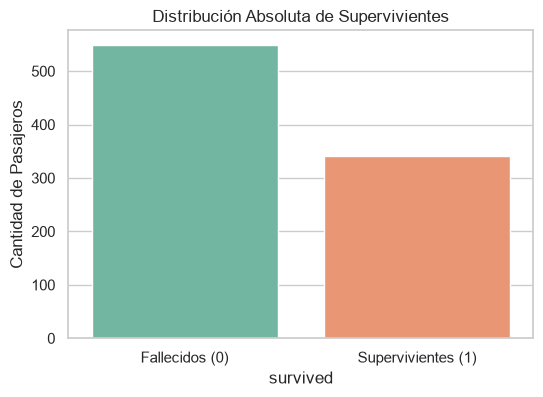

In [47]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4)) #tamaño del gráfico
sns.countplot(x='survived', data=df_titanic, hue='survived', palette='Set2', legend=False) #countplot es este tipo de gráfico de barras
plt.title('Distribución Absoluta de Supervivientes') #título de la gráfica
plt.xticks([0, 1], ['Fallecidos (0)', 'Supervivientes (1)']) #cambia las etiquetas del eje x
plt.ylabel('Cantidad de Pasajeros') #texto del eje y
plt.show()

### #2.2 Categórico Nominal 'who'

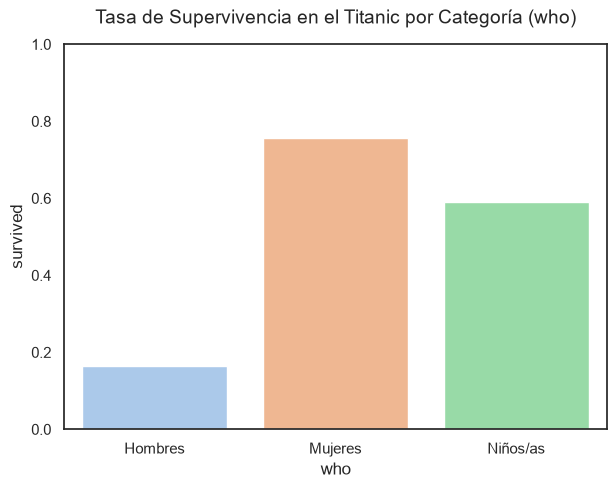

In [48]:
sns.set_theme(style="white")
plt.figure(figsize=(7, 5))
sns.barplot(x='who', y='survived', data=df_titanic, hue='who', palette='pastel', legend=False, errorbar=None)
plt.title('Tasa de Supervivencia en el Titanic por Categoría (who)', fontsize=14, pad=15)
plt.xticks([0, 1, 2], ['Hombres', 'Mujeres', 'Niños/as'])
plt.ylim(0, 1)
plt.show()

### #2.3 Categórico Ordinal 'class'

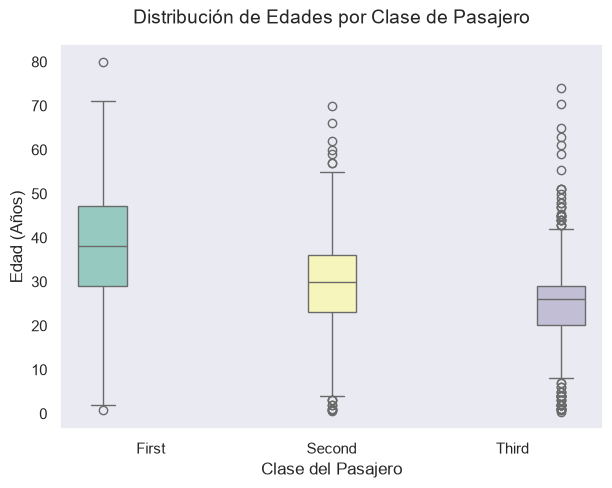

In [49]:
sns.set_theme(style="dark")
plt.figure(figsize=(7,5))
sns.boxplot(x='class', y='age', data=df_titanic, hue='class', palette='Set3', legend=False)
plt.title('Distribución de Edades por Clase de Pasajero', fontsize=14, pad=15)
plt.xlabel('Clase del Pasajero', fontsize=12)
plt.ylabel('Edad (Años)', fontsize=12)
plt.show()

### #2.4 Categórico Nominal 'embarked'

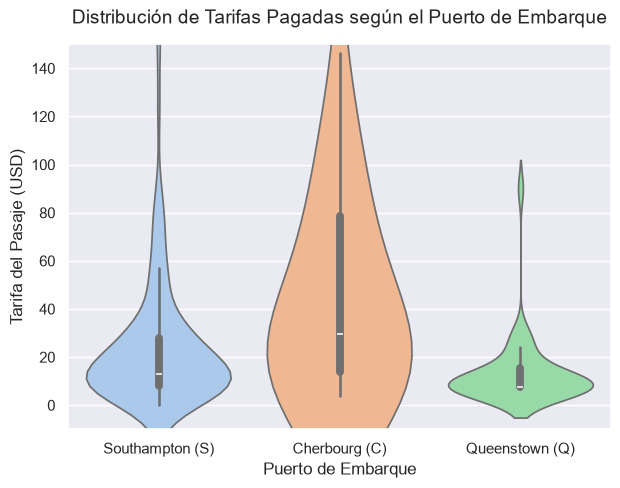

In [50]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(7,5))
sns.violinplot(x='embarked', y='fare', data=df_titanic, hue='embarked', palette='pastel', legend=False)
plt.title('Distribución de Tarifas Pagadas según el Puerto de Embarque', fontsize=14, pad=15)
plt.xlabel('Puerto de Embarque', fontsize=12)
plt.ylabel('Tarifa del Pasaje (USD)', fontsize=12)
plt.xticks([0,1,2],['Southampton (S)','Cherbourg (C)','Queenstown (Q)'])
plt.ylim(-10,150) # limitar el eje y
plt.show()

### #2.5 Categórico Binario 'alone'

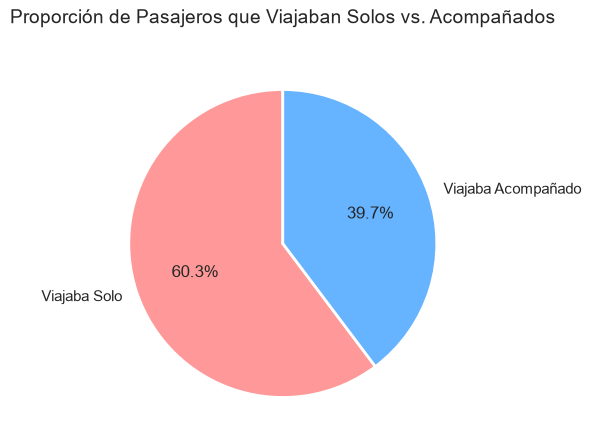

In [51]:
s_alone = df_titanic['alone'].value_counts()

plt.figure(figsize=(7,5))
colores = ['#ff9999', '#66b3ff']

plt.pie(
    s_alone, 
    labels=['Viajaba Solo','Viajaba Acompañado'], # etiquetas para cada sector
    autopct='%1.1f%%',                             # mostrar el porcentaje con un decimal
    startangle=90,                                 # rotar el inicio del gráfico
    colors=colores,                                # aplicar la paleta de colores
    wedgeprops={'edgecolor':'white', 'linewidth':2} # añadir una línea blanca de separación
)

plt.title('Proporción de Pasajeros que Viajaban Solos vs. Acompañados', fontsize=14, pad=20)
plt.show()

In [52]:
################### PRUEBA DE LIBRERIA PLOTLY ###################
import plotly.graph_objects as go

conteo = (df_titanic["alone"].map({True: "Viajaba solo", False: "Viajaba acompañado"}).value_counts().reindex(["Viajaba solo", "Viajaba acompañado"], fill_value=0))

fig = go.Figure(data=[go.Pie(
    labels=conteo.index,
    values=conteo.values,
    hole=0.58,
    sort=False,
    direction="clockwise",
    marker=dict(
        colors=["#5470C6", "#91CC75"],
        line=dict(color="white", width=3)
    ),
    textinfo="percent",
    textposition="inside",
    textfont=dict(size=15, color="white"),
    hovertemplate=(
    "&nbsp;&nbsp;<b>%{label}</b><br>"
    "&nbsp;&nbsp;Pasajeros: %{value}<br>"
    "&nbsp;&nbsp;Porcentaje: %{percent}"
    "<extra></extra>"
    )
)])

fig.update_layout(
    title=dict(
        text="<b>¿Cómo viajaban los pasajeros del Titanic?</b>"
             "<br><sup>Distribución de pasajeros según si viajaban solos o acompañados</sup>",
        x=0.5,
        xanchor="center"
    ),
    template="plotly_white",
    font=dict(family="Arial", size=13, color="#344054"),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.12,
        xanchor="center",
        x=0.5
    ),
    margin=dict(t=100, b=70, l=30, r=30),
    height=500,
    annotations=[
        dict(
            text=f"<b>{conteo.sum():,}</b><br><span style='font-size:12px'>Pasajeros</span>",
            x=0.5,
            y=0.5,
            font=dict(size=23, color="#344054"),
            showarrow=False
        )
    ]
)

fig.show()

### #2.6 Numérico Discreto 'age'

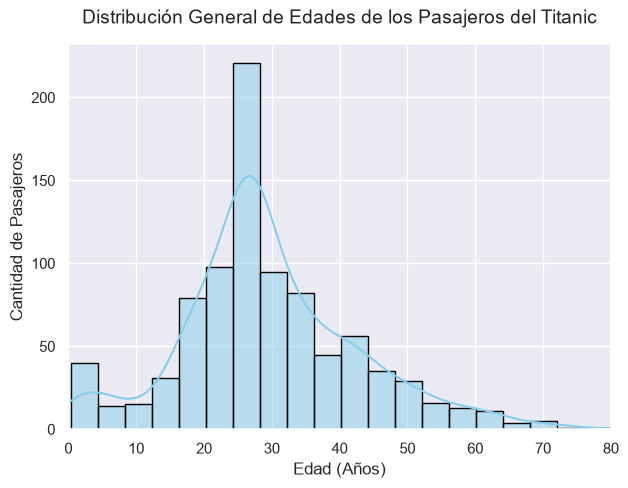

In [53]:
plt.figure(figsize=(7,5))

# bins=20 -> agrupa las edades en bloques de aproximadamente 4 años cada uno
# kde=True -> añade una línea que muestra la tendencia de la distribución
sns.histplot(data=df_titanic, x='age', bins=20, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribución General de Edades de los Pasajeros del Titanic', fontsize=14, pad=15)
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Cantidad de Pasajeros', fontsize=12)
plt.xlim(0, 80)
plt.show()

### #2.7 Numérico Continuo 'fare'

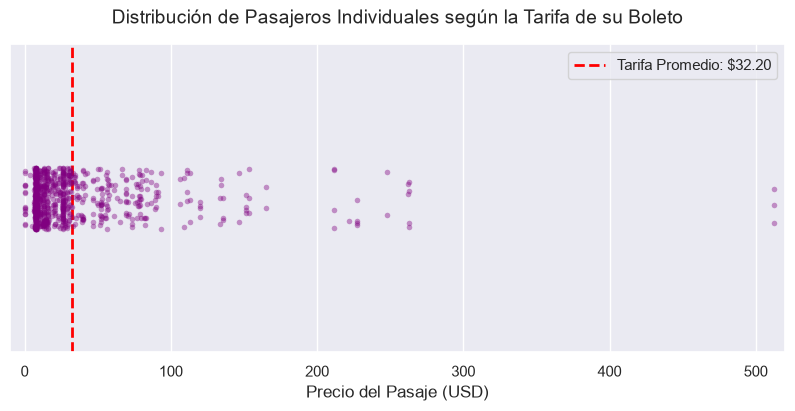

In [54]:
plt.figure(figsize=(10, 4))

# jitter=True -> dispersar los puntos verticalmente para que no se vean todos muy pegados
sns.stripplot(data=df_titanic, x='fare', color='purple', alpha=0.4, size=4, jitter=True)

fare_media = df_titanic['fare'].mean()
plt.axvline(fare_media, color='red', linestyle='--', linewidth=2, label=f'Tarifa Promedio: ${fare_media:.2f}') # línea roja

plt.title('Distribución de Pasajeros Individuales según la Tarifa de su Boleto', fontsize=14, pad=15)
plt.xlabel('Precio del Pasaje (USD)', fontsize=12)
plt.legend() # mostrar cuadro para explicar la línea roja
plt.xlim(-10, 520)
plt.gca().axes.get_yaxis().set_visible(False) # ocultar el eje y
plt.show()